## LAB ASSIGNMENT

Name: Joseph Atem Deng Aruei

Nim: 244107020242

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

Load Data

In [5]:
data = pd.read_csv('insurance.csv')

# Dataset overview
print("First five rows:")
print(data.head())
print("\nDataset shape:", data.shape)
print("\nColumn information:")
data.info()
print("\nNumeric summary:")
print(data.describe())

First five rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Dataset shape: (1338, 7)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

Numeric summary:
               age          b

In [6]:
# Features: age, sex, bmi, children, smoker, region
# Target: charges (personal medical cost)
X = data.drop(columns="charges")
y = data["charges"]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()


def make_preprocessor():
    """Scale numeric features and one-hot encode categorical features."""
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), numeric_features),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore"),
                categorical_features,
            ),
        ]
    )

In [7]:
# Hold out 20% of the data for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    return {
        "Model": name,
        "R-squared": r2_score(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
    }, predictions

In [8]:
# Multiple linear regression
linear_model = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        ("regressor", LinearRegression()),
    ]
)
linear_model.fit(X_train, y_train)

linear_results, linear_predictions = evaluate_model(
    "Multiple Linear Regression", linear_model, X_test, y_test
)

In [9]:
# SVR with hyperparameter tuning.
# Preprocessing is inside the pipeline, so each CV fold fits it using only
# that fold's training data.
svr_pipeline = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        ("regressor", SVR()),
    ]
)

parameter_grid = {
    "regressor__kernel": ["rbf"],
    "regressor__C": [1, 10, 100, 1000],
    "regressor__epsilon": [0.1, 1, 10],
    "regressor__gamma": ["scale", "auto"],
}

svr_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=parameter_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
)
svr_search.fit(X_train, y_train)

best_svr_model = svr_search.best_estimator_
svr_results, svr_predictions = evaluate_model(
    "Tuned SVR", best_svr_model, X_test, y_test
)

print("\nBest SVR parameters:")
print(svr_search.best_params_)


Best SVR parameters:
{'regressor__C': 1000, 'regressor__epsilon': 10, 'regressor__gamma': 'auto', 'regressor__kernel': 'rbf'}


In [10]:
# Present evaluation results
results = pd.DataFrame([linear_results, svr_results]).set_index("Model")
print("\nTest-set evaluation results:")
print(results.round(3))


Test-set evaluation results:
                            R-squared           MSE       MAE
Model                                                        
Multiple Linear Regression      0.784  3.359692e+07  4181.194
Tuned SVR                       0.589  6.379086e+07  3423.299


In [11]:
# A higher R-squared and lower MSE/MAE indicate better test-set predictions.
best_model_name = results["R-squared"].idxmax()
print(f"\nHighest test-set R-squared: {best_model_name}")



Highest test-set R-squared: Multiple Linear Regression


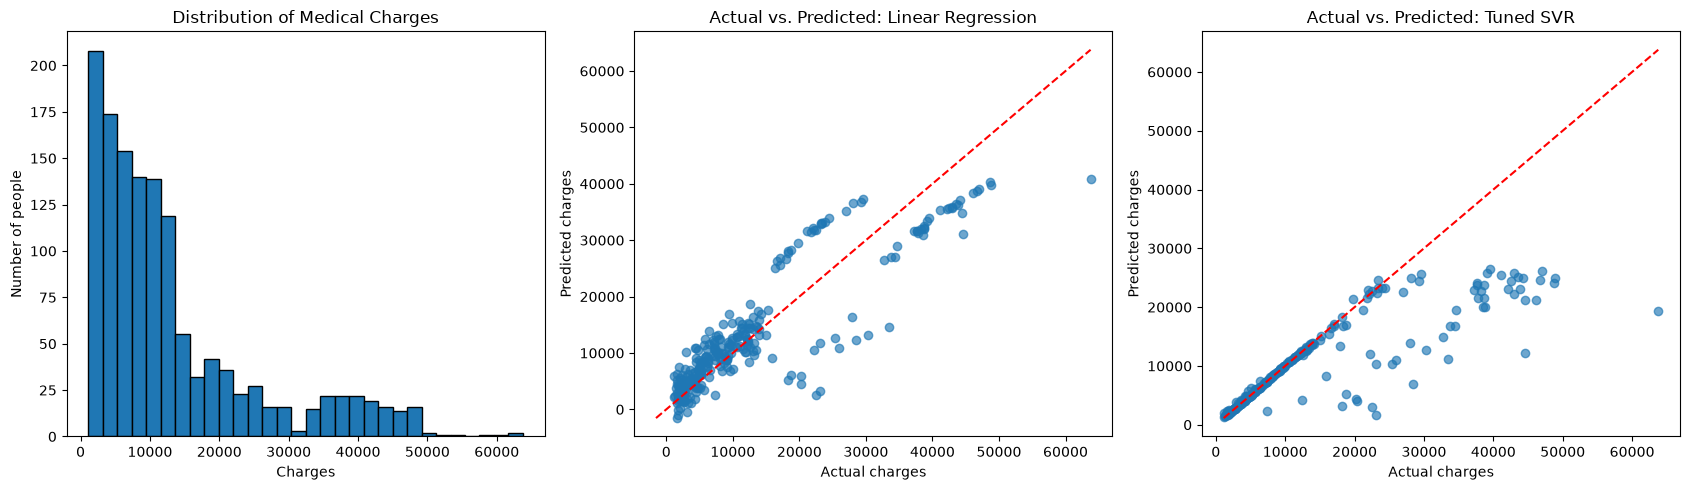

In [12]:
# Visualizations: charges distribution and actual vs. predicted costs
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(y, bins=30, edgecolor="black")
axes[0].set_title("Distribution of Medical Charges")
axes[0].set_xlabel("Charges")
axes[0].set_ylabel("Number of people")

plot_data = [
    ("Linear Regression", linear_predictions),
    ("Tuned SVR", svr_predictions),
]

for ax, (title, predictions) in zip(axes[1:], plot_data):
    ax.scatter(y_test, predictions, alpha=0.65)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(f"Actual vs. Predicted: {title}")
    ax.set_xlabel("Actual charges")
    ax.set_ylabel("Predicted charges")

plt.tight_layout()
plt.show()